# Python ile Karar Ağacı Oluşturma

## Yol Haritası

1. **Python'a İlk Adım** — Ekrana yazı yazdırma, değişkenler, listeler
2. **Kütüphaneleri Tanıma** — Hazır araçları nasıl kullanırız?
3. **Veriyi Tanıma** — Yiyecek verimizi okuyalım, inceleyelim
4. **Veriyi Eğitim ve Test Olarak Ayırma** — CODAP'ta yaptığınızın aynısı
5. **İlk Karar Ağacımız** — Eğitim verisiyle eğitelim, test verisiyle değerlendirelim
6. **Derinliği Siz Seçin** — Farklı derinlikleri deneyin
7. **Optimum Derinliği Bulma** — Tüm derinlikleri otomatik karşılaştırma

> **Not:** Eğer kodda takıldığınız bir yer olursa, hata mesajını okuyun.
> Hata mesajları, problemi tarif eden dostunuzdur, düşmanınız değil.

# 1. Python'a İlk Adım

Python'da en temel komut bir şeyi **ekrana yazdırmaktır**. Bunu `print()` fonksiyonu ile yaparız.

> **Fonksiyon nedir?** Bir işi yapan hazır komuttur. Tıpkı hesap makinesindeki
> "√" tuşu gibi: parantez içine bir sayı yazarsınız, fonksiyon size karekökünü verir.

## 1.1 İlk Komut: Ekrana Yazı Yazdırma

In [26]:
# print fonksiyonu, parantez içindeki şeyi ekrana yazar.
# Tırnak içine yazılan şey "metin"dir (string).

print("Merhaba dünya!")

Merhaba dünya!


**Şimdi sıra sizde:** Aşağıdaki hücredeki tırnak içine kendi adınızı yazın
ve `Shift + Enter` ile çalıştırın.

In [27]:
print("Merhaba, ben Instructor!")  # Kendi adınızı yazın

Merhaba, ben Instructor!


## 1.2 Değişkenler — Bilgileri Saklama

Değişken, bir bilgiyi içine koyduğumuz "kutu" gibidir. Kutuya bir isim veririz,
sonra o isimle bilgiye ulaşırız.

> **Matematiksel benzetme:** $x = 5$ yazdığınızda $x$ bir değişkendir.
> Python'da da aynısını `x = 5` şeklinde yazarız.

In [28]:
# = işareti ile değişken oluştururuz.
yas = 21
isim = "Amy"

print(isim)
print(yas)

Amy
21


> **Dikkat:** Sayılar tırnak içine yazılmaz. Metinler ise her zaman tırnak içine yazılır.

**Sıra sizde:** Aşağıda kendi yaşınızı ve favori yiyeceğinizi değişkenlere atayın.

In [29]:
benim_yasim = 0          # Kendi yaşınızı yazın
favori_yiyecek = ""      # Tırnak içine favori yiyeceğinizi yazın

print("Yaşım:", benim_yasim)
print("Favori yiyeceğim:", favori_yiyecek)

Yaşım: 0
Favori yiyeceğim: 


## 1.3 Listeler — Birden Fazla Değer Saklama

Bir yiyecek listemiz olsun. Tek tek değişken oluşturmak yerine **liste** kullanırız.
Liste, köşeli parantez `[ ]` içinde, virgülle ayrılmış elemanlardan oluşur.

In [30]:
# Bir liste oluşturalım
yiyecekler = ["Elma", "Çikolata", "Brokoli", "Cips"]

print(yiyecekler)
print("Listede", len(yiyecekler), "yiyecek var.")  # len = uzunluk (length)

['Elma', 'Çikolata', 'Brokoli', 'Cips']
Listede 4 yiyecek var.


> `len()` fonksiyonu, bir listenin kaç elemanı olduğunu söyler.

**Tartışma:** Eğer 4 yerine 100 yiyecek olsaydı, tek tek değişken oluşturmak
mantıklı olur muydu? İşte bu yüzden **listeler** ve birazdan göreceğimiz
**tablolar (DataFrame)** çok önemli.

# 2. Kütüphaneleri Tanıma

Python'da her şeyi sıfırdan yazmayız. **Kütüphaneler**, başkalarının yazdığı
hazır araç kutularıdır. Onları içe aktarır (`import`) ve kullanırız.

| Kütüphane | Ne işe yarar? |
|-----------|---------------|
| `pandas` | Tablolarla çalışmak (Excel gibi düşünün) |
| `matplotlib` | Grafik çizmek |
| `sklearn` | Makine öğrenmesi modelleri (karar ağacı dahil) |

> **Benzetme:** `pandas` bir mutfak gibidir. `import pandas as pd` demek,
> "mutfağı `pd` kısa adıyla çağırabileyim" demektir.

In [31]:
# Bu derste kullanacağımız kütüphaneleri içe aktaralım.
# Bu hücreyi bir kez çalıştırmanız yeterli.

import pandas as pd                                    # Tablolar için
import matplotlib.pyplot as plt                        # Grafikler için
from sklearn.tree import DecisionTreeClassifier        # Karar ağacı modeli
from sklearn.tree import plot_tree                     # Ağacı çizmek için
from sklearn.model_selection import train_test_split   # Veriyi bölmek için
from sklearn.metrics import accuracy_score             # Doğruluk hesaplamak için
from sklearn.metrics import confusion_matrix           # Confusion matrix için
from sklearn.metrics import ConfusionMatrixDisplay     # Confusion matrix grafiği

print("Kütüphaneler başarıyla yüklendi.")

Kütüphaneler başarıyla yüklendi.


> Eğer yukarıdaki hücreyi çalıştırırken hata alırsanız, Colab'ın internete
> bağlı olduğundan emin olun. Bu kütüphanelerin hepsi Colab'da hazır gelir.

pip install pandas

# 3. Veriyi Tanıma

Şimdi yiyecek verimizi yükleyeceğiz. Bu veride **55 yiyecek** var ve her yiyecek için:

- Enerji (kcal)
- Yağ (g)
- Doymuş Yağ (g)
- Karbonhidrat (g)
- Şeker (g)
- Protein (g)
- Tuz (g)
- **Öneri** (Tavsiye edilebilir / Tavsiye edilemez)

**Hedefimiz:** Bu 7 sayısal bilgiye bakarak bir yiyeceğin **tavsiye edilip edilemeyeceğini**
otomatik olarak öğrenen bir karar ağacı yapmak.

## 3.1 Veriyi Colab'a Yükleme

**Yapmanız gerekenler:**

1. Sol kenardaki **Dosyalar** ikonuna tıklayın.
2. Açılan panelin üstündeki **yukarı ok (Yükle)** butonuna tıklayın.
3. Bilgisayarınızdan `Food_Dataset_Turkish.csv` dosyasını seçin.
4. Yükleme bittikten sonra aşağıdaki hücreyi çalıştırın.

> **Önemli:** Colab oturumu kapandığında yüklediğiniz dosya silinir.
> Her yeni oturumda dosyayı tekrar yüklemeniz gerekir.

In [32]:
# Veriyi okuyalım. pd.read_csv fonksiyonu CSV dosyasını okur ve tablo haline getirir.
df = pd.read_csv("Food_Dataset_Turkish.csv")

# df = "DataFrame" kelimesinin kısaltması. Bir tablo demek.
# İlk 5 satıra bakalım:
df.head()
# Son 5 satıra bakalım:
df.tail()

,Ürün Adı,Enerji (kcal),Yağ (g),Doymuş Yağ (g),Karbonhidrat (g),Şeker (g),Protein (g),Tuz (g),Öneri
50,Bitter Çikolata,582,43.0,26.0,37.0,29.0,6.7,0.0,Tavsiye edilemez
51,Domates,19,0.1,0.0,3.5,3.2,0.7,0.0,Tavsiye edilebilir
52,Sandviç Bisküvi,470,18.5,8.6,68.7,32.4,5.4,0.4,Tavsiye edilemez
53,Karamelli Şeker,424,8.4,5.7,86.9,71.6,0.3,1.0,Tavsiye edilemez
54,Kabak,19,0.4,0.1,2.2,1.6,1.6,0.0,Tavsiye edilebilir


> `df.head()` ilk 5 satırı, `df.tail()` son 5 satırı gösterir.
> `df.head(10)` derseniz ilk 10 satırı verir.

## 3.2 Veri Hakkında Genel Bilgi

In [33]:
# Veride kaç satır ve kaç sütun var?
print("Satır sayısı (yiyecek sayısı):", df.shape[0])
print("Sütun sayısı (özellik sayısı):", df.shape[1])
print()
print("Sütun isimleri:")
print(df.columns.tolist())

Satır sayısı (yiyecek sayısı): 55
Sütun sayısı (özellik sayısı): 9

Sütun isimleri:
['Ürün Adı', 'Enerji (kcal)', 'Yağ (g)', 'Doymuş Yağ (g)', 'Karbonhidrat (g)', 'Şeker (g)', 'Protein (g)', 'Tuz (g)', 'Öneri']


In [34]:
# Her sınıftan kaç tane var? (Sınıf dengesi önemli.)
df["Öneri"].value_counts()

,count
Öneri,
Tavsiye edilemez,29
Tavsiye edilebilir,26


**Tartışma sorusu:** Tavsiye edilebilir ve edilemez yiyeceklerin sayıları
yaklaşık eşit mi, yoksa biri çok daha fazla mı? Bu durum modelimizi nasıl etkiler?

## 3.3 Sayısal Özet

In [35]:
# describe() bize her sayısal sütun için ortalama, min, max gibi istatistikleri verir.
df.describe().round(1)

,Enerji (kcal),Yağ (g),Doymuş Yağ (g),Karbonhidrat (g),Şeker (g),Protein (g),Tuz (g)
count,55.0,55.0,55.0,55.0,55.0,55.0,55.0
mean,288.2,15.4,5.9,29.0,11.5,7.2,0.9
std,201.1,20.9,9.8,28.3,18.0,6.2,1.2
min,7.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,106.0,0.5,0.1,3.2,0.8,1.6,0.0
50%,279.0,7.3,1.5,18.0,2.3,6.4,0.3
75%,405.5,22.5,6.8,54.5,13.5,11.2,1.6
max,743.0,82.0,55.0,86.9,71.6,24.0,5.5


**Tartışma:** Şeker miktarı en yüksek olan yiyecek hangisi sizce?
Aşağıda kontrol edelim.

In [36]:
# Şekere göre azalan sıralama
df.sort_values("Şeker (g)", ascending=False).head(5)

,Ürün Adı,Enerji (kcal),Yağ (g),Doymuş Yağ (g),Karbonhidrat (g),Şeker (g),Protein (g),Tuz (g),Öneri
53,Karamelli Şeker,424,8.4,5.7,86.9,71.6,0.3,1.0,Tavsiye edilemez
31,Hurma,279,0.2,0.1,73.0,60.0,2.2,0.0,Tavsiye edilebilir
26,Sütlü Çikolata,530,29.5,17.5,58.5,57.5,6.6,0.2,Tavsiye edilemez
38,Ahududu Reçeli,223,0.2,0.0,52.2,51.7,0.7,0.0,Tavsiye edilemez
35,Jelibon,343,0.1,0.1,77.0,46.0,6.9,0.1,Tavsiye edilemez


In [37]:
# Yağa göre artan sıralama
df.sort_values("Yağ (g)", ascending=True).head(5)

,Ürün Adı,Enerji (kcal),Yağ (g),Doymuş Yağ (g),Karbonhidrat (g),Şeker (g),Protein (g),Tuz (g),Öneri
10,Göbek Marul,7,0.0,0.0,0.7,0.7,0.5,0.0,Tavsiye edilebilir
20,Salatalık,12,0.1,0.0,3.6,1.7,0.7,0.0,Tavsiye edilebilir
25,Patates,71,0.1,0.0,15.0,0.8,1.7,2.0,Tavsiye edilebilir
35,Jelibon,343,0.1,0.1,77.0,46.0,6.9,0.1,Tavsiye edilemez
51,Domates,19,0.1,0.0,3.5,3.2,0.7,0.0,Tavsiye edilebilir


# 4. Veriyi Modele Hazırlama ve Ayırma

Bu bölüm **iki adımdan** oluşur. Her ikisi de CODAP'ta yaptığınızın aynısı.

## 4.1 Özellikler (X) ve Hedef (y)

Karar ağacı modeli iki şey ister:

- **X (Özellikler / Features):** Modele bakacağı bilgiler — burada 7 sayısal sütun.
- **y (Hedef / Target):** Modelin tahmin edeceği şey — burada **Öneri** sütunu.

> **Hatırlatma:** CODAP'ta da aynı şeyi yapmıştınız. Sütunlara bakıp hangisini tahmin
> edeceğinize karar vermiştiniz.

In [38]:
# Özellikler (X): Ürün Adı ve Öneri dışındaki tüm sütunlar
X = df.drop(columns=["Ürün Adı", "Öneri"])

# Hedef (y): Sadece Öneri sütunu
y = df["Öneri"]

print("X (özellikler) ilk 3 satır:")
print(X.head(3))
print()
print("y (hedef) ilk 3 değer:")
print(y.head(3).tolist())

X (özellikler) ilk 3 satır:
   Enerji (kcal)  Yağ (g)  Doymuş Yağ (g)  Karbonhidrat (g)  Şeker (g)  \
0            542     31.9            18.6              54.0       42.6   
1            499     23.0            13.8              57.0        3.8   
2             52      0.2             0.0              13.8       11.0   

   Protein (g)  Tuz (g)  
0          7.6      0.4  
1         10.7      1.8  
2          0.3      0.0  

y (hedef) ilk 3 değer:
['Tavsiye edilemez', 'Tavsiye edilemez', 'Tavsiye edilebilir']


> **Neden Ürün Adı'nı çıkardık?**
> Çünkü "Elma" yazısı bir sayı değil. Karar ağacı sayılarla karar verir.
> Ayrıca, ürün adından öğrenmek istemiyoruz — biz besin değerlerinden öğrenmek istiyoruz.

## 4.2 Eğitim ve Test Ayrımı

**Bu çok önemli bir adımdır.** CODAP'ta da yapmıştınız: verinin bir kısmıyla
modeli eğitiriz, geri kalan kısmıyla **modelin daha önce görmediği veriler üzerinde**
ne kadar başarılı olduğunu test ederiz.

> **Sınav benzetmesi:**
> - **Eğitim verisi (train):** Öğrencinin çalıştığı ders notları
> - **Test verisi:** Sınav soruları
>
> Aynı sorularla hem çalışıp hem sınav olmak adil değildir. Modelin gerçek başarısı
> ancak **görmediği** veride ölçülebilir.

CODAP'ta yaptığınız gibi **%80 eğitim, %20 test** olacak şekilde böleceğiz.

In [39]:
# Veriyi ikiye böl: %80 eğitim, %20 test
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,        # %20'si test olsun
    random_state=42,      # Aynı sonucu almak için sabit sayı (Hitchhiker's Guide to the Galaxy—Otostopçunun Galaksi Rehberi)
    stratify=y            # İki sınıftan da orantılı al
)

print(f"Eğitim seti büyüklüğü: {len(X_egitim)} yiyecek")
print(f"Test seti büyüklüğü:    {len(X_test)} yiyecek")
print()
print("Eğitim setindeki sınıf dağılımı:")
print(y_egitim.value_counts())
print()
print("Test setindeki sınıf dağılımı:")
print(y_test.value_counts())

Eğitim seti büyüklüğü: 44 yiyecek
Test seti büyüklüğü:    11 yiyecek

Eğitim setindeki sınıf dağılımı:
Öneri
Tavsiye edilemez      23
Tavsiye edilebilir    21
Name: count, dtype: int64

Test setindeki sınıf dağılımı:
Öneri
Tavsiye edilemez      6
Tavsiye edilebilir    5
Name: count, dtype: int64


> **Önemli parametreler:**
> - `test_size=0.2` → verinin %20'si test seti olur.
> - `random_state=42` → her çalıştırdığımızda aynı bölünmeyi alırız. 42 yerine
>   başka bir sayı da olabilir; önemli olan **sabit bir sayı** olması.
> - `stratify=y` → her iki sınıftan da orantılı bölünme sağlar. Bu olmadan,
>   şanssız bir bölünmede tüm "Tavsiye edilemez"ler test setine düşebilir.

**Tartışma:** Test setinizin sınıf dağılımı, eğitim setinin dağılımına benziyor mu?
`stratify=y` parametresi olmasaydı ne olurdu?

# 5. İlk Karar Ağacımız

Şimdi ilk ağacımızı oluşturalım.

> **Hatırlatma:** CODAP'ta ağacın **derinliğini** (kaç soru üst üste sorulacağını)
> siz seçiyordunuz. Burada da aynısını yapacağız: `max_depth` parametresi
> bunu kontrol eder.

In [40]:
# Tek Seviyeli Karar Ağacı Oluşturma
agac1 = DecisionTreeClassifier(max_depth=1, random_state=42)

# Ağacı EĞİTİM verisi ile eğitelim (fit = eğitmek)
agac1.fit(X_egitim, y_egitim)

print("Tek seviyeli karar ağacımız eğitildi.")

Tek seviyeli karar ağacımız eğitildi.


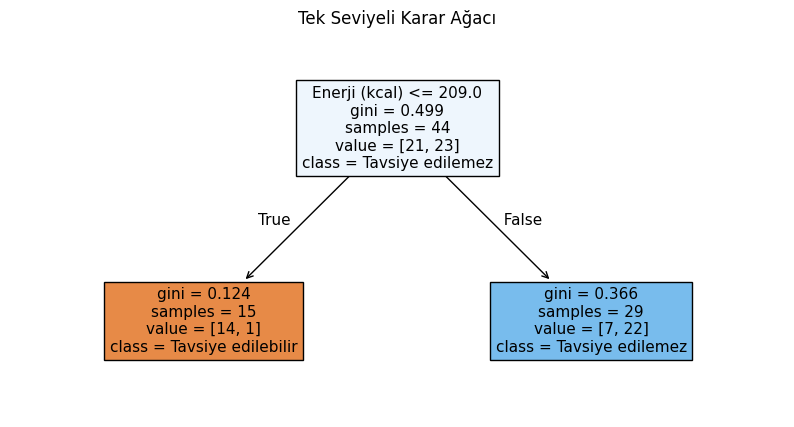

In [16]:
# Karar ağacını çizme (Bilgilendirme notu)
plt.figure(figsize=(10,5))                # Tuval boyutunu ayarlar
plot_tree(agac1,                          # Çizimi başlatır
          feature_names=X.columns,        # Değişken isimlerini ekler
          class_names=agac1.classes_,     # hedef değişkenin isimlerini belirtir
          filled=True,                    # Kutuları renklendirir
          fontsize=11)                    # Yazı boyutunu belirler
plt.title("Tek Seviyeli Karar Ağacı")     # Grafiğe başlık ekler
plt.show()                                # Grafiği ekranda gösterir

# Tek seviyeli karar ağacı ne kadar başarılı?

## Duyarlılık (Sensitivity) Değerlerini Hesaplayalım

In [17]:
tahminler_egitim = agac1.predict(X_egitim)
tahminler_test = agac1.predict(X_test)

In [18]:
from sklearn.metrics import recall_score

# Benim için pozitif olan (odaklandığım) sınıf 'Tavsiye edilebilir'dir.
# Hesaplamayı buna göre yapacağız. pos_label = positive_label = 'Tavsiye edilebilir

# Eğitim verisinde duyarlılık (sensitivity) hesaplama
duyarlilik_egitim1 = recall_score(y_egitim, tahminler_egitim, pos_label='Tavsiye edilebilir')

# Test verisinde duyarlılık (sensitivity) hesaplama
duyarlilik_test1 = recall_score(y_test, tahminler_test, pos_label='Tavsiye edilebilir')

print(f"Eğitim duyarlılık: {duyarlilik_egitim1:.2%}")
print(f"Test duyarlılık: {duyarlilik_test1:.2%}")

Eğitim duyarlılık: 66.67%
Test duyarlılık: 80.00%


Misclassification Rate - MCR Değerini Hesaplayalım

**MCR = 1 - Accuracy**

In [19]:
from sklearn.metrics import accuracy_score

# Eğitim verisinde MCR hesaplama
mcr_egitim1 = 1 - accuracy_score(y_egitim, tahminler_egitim)

# Test verisinde MCR hesaplama
mcr_test1 = 1 - accuracy_score(y_test, tahminler_test)

print(f"Eğitim yanlış sınıflandırma oranı: {mcr_egitim1:.2%}")
print(f"Test yanlış sınıflandırma oranı: {mcr_test1:.2%}")

Eğitim yanlış sınıflandırma oranı: 18.18%
Test yanlış sınıflandırma oranı: 27.27%


**Tartışma:**
- İki doğruluk arasında fark var mı?
- Hangisi daha önemli sizce, neden?

# 6. Derinliği Siz Seçin

Şimdi siz karar verin: ağaç ne kadar derin olsun?

> **Düşünme zamanı:**
> - Derinlik küçükse, ağaç çok basittir, belki çok kaba kararlar verir (underfitting).
> - Derinlik büyükse, ağaç çok detaylıdır, belki ezbere öğrenir (overfitting).

In [20]:
# Derinliğini benim seçtiğim karar ağacını oluşturma
benim_secimim = 3   # BURAYI DEĞİŞTİR

# Tek Seviyeli Karar Ağacı Oluşturma
agac2 = DecisionTreeClassifier(max_depth=benim_secimim, random_state=42)

# Ağacı EĞİTİM verisi ile eğitelim (fit = eğitmek)
agac2.fit(X_egitim, y_egitim)

print("Çok seviyeli karar ağacımız eğitildi.")

Çok seviyeli karar ağacımız eğitildi.


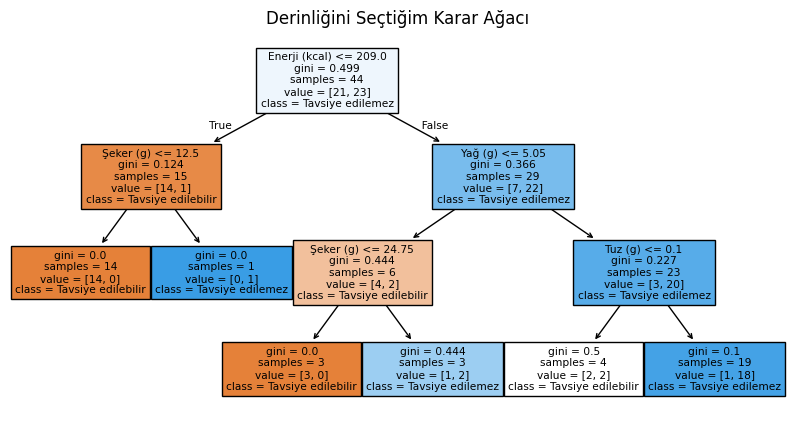

In [21]:
# Karar ağacını çizme

plt.figure(figsize=(10,5))                        # Tuval boyutunu ayarlar
plot_tree(agac2,                                  # Çizimi başlatır
          feature_names=X.columns,                # Değişken isimlerini ekler
          class_names=agac1.classes_,             # hedef değişkenin isimlerini belirtir
          filled=True)                            # Kutuları renklendirir
plt.title("Derinliğini Seçtiğim Karar Ağacı")     # Grafiğe başlık ekler
plt.show()                                        # Grafiği ekranda gösterir

# For Döngüleri
Diyelim ki elinizde 5 farklı anahtar var ve bir kapıyı açmaya çalışıyorsunuz. Beyniniz size şu talimatı vermez:

1. anahtarı al, dene.

2. anahtarı al, dene.

3. anahtarı al, dene...

Bunun yerine beyniniz çok daha pratik bir kural koyar:

- 'Elimdeki anahtarlıkta bulunan HER BİR anahtar İÇİN sırayla kapıyı açmayı dene.'

İşte Python'daki for döngüsü tam olarak budur! Tekrar eden, sıkıcı işlemleri alt alta defalarca yazmak yerine bilgisayara 'Şu listedeki her bir eleman için sırayla şu işlemleri yap' dememizi sağlar.

In [22]:
ogrenciler = ["Melinda", "Marcus", "Zara", "Ulysses"]

for ogrenci in ogrenciler:
    print("Merhaba " + ogrenci + "!")

Merhaba Melinda!
Merhaba Marcus!
Merhaba Zara!
Merhaba Ulysses!


# 7. Optimum Derinliği Bulma

Tek tek deneyip not almak yerine, Python'a hepsini sırayla yaptıralım.

> **Döngü (loop):** Aynı işlemi farklı değerlerle tekrar tekrar yapmak için kullanılır.
> "Derinlik 1, 2, 3, ..., 10 için ağaç kur, doğrulukları hesapla, kaydet" demek istiyoruz.

## 7.1 Tüm derinlikleri otomatik dene

In [23]:
# Sonuçları saklamak için boş listeler, döngüyü çalıştırdıktan sonra için değerleri ekleyeceğiz.
sonuclar_egitim = []
sonuclar_test = []

derinlikler = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]  # Deneyeceğimiz derinlikler

In [24]:
# Döngü başlıyor! Aşağıdaki kodlar her bir derinlik için tekrar tekrar çalışacak.

for derinlik in derinlikler:
    # 1. Ağacı o anki derinliğe göre oluşturma
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)

    # 2. Ağacı eğitme
    agac.fit(X_egitim, y_egitim)

    # 3. MCR değerlerini hesaplama
    mcr_egitim = 1 - accuracy_score(y_egitim, agac.predict(X_egitim))
    mcr_test = 1 - accuracy_score(y_test, agac.predict(X_test))

    # 4. Sonuçları listelere ekle
    sonuclar_egitim.append(mcr_egitim)
    sonuclar_test.append(mcr_test)

    # 5. Ekrana yazdır
    print(f"Derinlik {derinlik} -> Eğitim: {mcr_egitim:.2%} | Test: {mcr_test:.2%}")

Derinlik 1 -> Eğitim: 18.18% | Test: 27.27%
Derinlik 2 -> Eğitim: 11.36% | Test: 9.09%
Derinlik 3 -> Eğitim: 9.09% | Test: 9.09%
Derinlik 4 -> Eğitim: 2.27% | Test: 18.18%
Derinlik 5 -> Eğitim: 2.27% | Test: 18.18%
Derinlik 6 -> Eğitim: 2.27% | Test: 18.18%
Derinlik 7 -> Eğitim: 2.27% | Test: 18.18%
Derinlik 8 -> Eğitim: 2.27% | Test: 18.18%
Derinlik 9 -> Eğitim: 2.27% | Test: 18.18%
Derinlik 10 -> Eğitim: 2.27% | Test: 18.18%


**Tabloya bakın ve düşünün:**
- Eğitim veri setinde derinlik arttıkça MCR nasıl değişiyor?
- Test veri setinde MCR nasıl değişiyor?
- En düşük test MCR hangi derinlikte?

## 7.2 Sonuçları grafikle görelim

Aşağıdaki hücrede grafiği çizdirmek için biraz Ulysses bir kod göreceksiniz. Bu kodları ezberlemenize veya tek tek anlamanıza hiç gerek yok! Profesyoneller de bu kodları her seferinde sıfırdan yazmaz, kopyala-yapıştır yaparlar veya hazır kütüphaneler kullanırlar. Bizim odaklanacağımız yer kodun kendisi değil, bize vereceği grafiğin yorumudur.

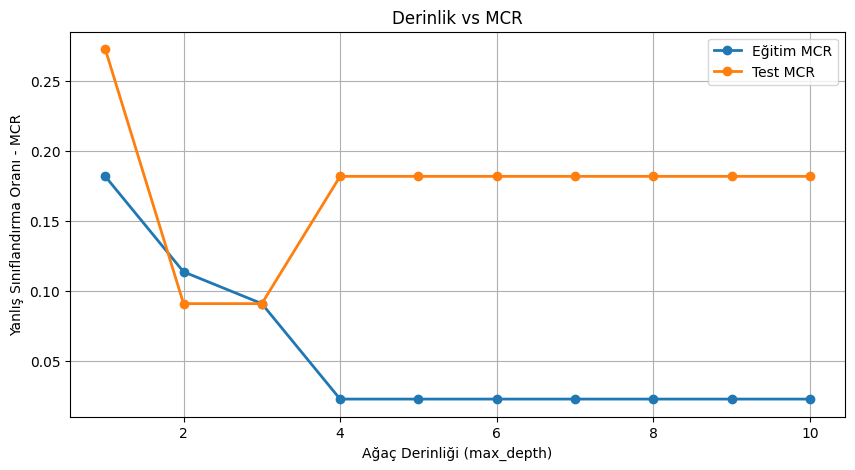

In [25]:
plt.figure(figsize=(10, 5))
plt.plot(derinlikler, sonuclar_egitim, marker="o", label="Eğitim MCR")
plt.plot(derinlikler, sonuclar_test, marker="o", label="Test MCR")
plt.xlabel("Ağaç Derinliği (max_depth)")
plt.ylabel("Yanlış Sınıflandırma Oranı - MCR")
plt.title("Derinlik vs MCR")
plt.legend()
plt.grid(True)
plt.show()

**Çok Önemli Tartışma — Overfitting (Aşırı Öğrenme):**

1. Eğitim doğruluğu (mavi çizgi) genelde nasıl gidiyor?
2. Test doğruluğu (turuncu çizgi) belli bir noktadan sonra ne yapıyor?
3. İki çizgi belli bir noktadan sonra **ayrışıyor** mu? Bu ne anlama geliyor?
4. **Sizin için en iyi (optimum) derinlik kaç?**

> **Pedagojik bağlantı — Ezber yapan öğrenci:**
> Eğitim doğruluğunun yüksek, test doğruluğunun düşük olması, bir öğrencinin
> ders notlarını ezberleyip sınavda yeni sorularla karşılaştığında zorlanmasına benzer.
> Buna **overfitting (aşırı öğrenme)** diyoruz.
>
> Bizim hedefimiz **ezber yapmadan genelleyebilen** bir model — yani test
> doğruluğu en yüksek olduğu derinlik.

Bugün şunları başardınız:

- Python'da ilk kodlarınızı yazdınız
- Bir CSV dosyasını okudunuz ve incelediniz
- Veriyi eğitim ve test setlerine ayırdınız (CODAP'ta öğrendiğiniz prensiple)
- Gerçek bir karar ağacı modeli kurdunuz
- Farklı derinlikleri deneyerek **en iyi modeli buldunuz**
- **Overfitting** (aşırı öğrenme) kavramını grafikle gördünüz

## Düşünme Soruları

1. CODAP'ta manuel kurduğunuz ağaç ile Python'un kurduğu ağaç **aynı özelliği** mi seçti?
2. Karar ağacı bir matematik öğretmeni olarak öğrencilere **hangi konuyu** anlatmak için kullanılabilir?
3. Bu ağaç bir kantinde "hangi yiyecekler tavsiye edilsin?" kararına yardım edebilir mi?
   **Etik olarak** bunda bir sorun var mı?